# 01 — Toy Pong, visually

Same RL loop, but now the state has several numbers at once: paddle position, ball position, and ball velocity.

You will see why **state representation** starts to matter.


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">Toy Pong</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">BALL + PADDLES</text><rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="15">NUMERIC STATE</text><rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="15">POLICY</text><rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="15">UP / STAY / DOWN</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="405.0" y1="82" x2="467.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="630.0" y1="82" x2="692.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>


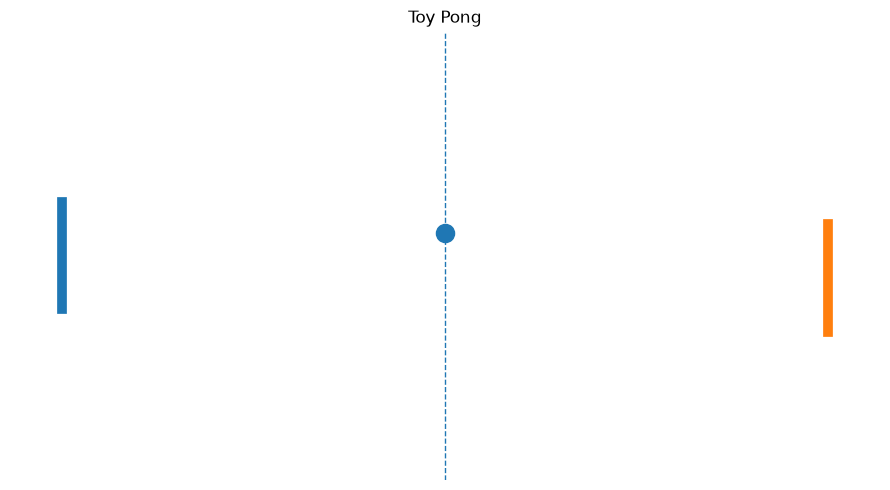

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
repo = Path.cwd()
if repo.name == "notebooks": repo = repo.parent
sys.path.insert(0, str(repo))
from visuals import pipeline, compare_bars

def draw_pong(player_y=0.5, ball_x=0.5, ball_y=0.55, opp_y=0.45, title="Toy Pong"):
    fig, ax = plt.subplots(figsize=(9,5))
    ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis("off")
    ax.plot([0.06,0.06],[player_y-0.12,player_y+0.12], linewidth=7)
    ax.plot([0.94,0.94],[opp_y-0.12,opp_y+0.12], linewidth=7)
    ax.scatter([ball_x],[ball_y],s=170)
    ax.axvline(0.5, linestyle="--", linewidth=1)
    ax.set_title(title)
    plt.tight_layout()
    return fig

fig = draw_pong()
plt.show()

## 1. A useful engineered state

Instead of pixels, we can hand the policy a compact vector:

`[player_y, ball_x, ball_y, ball_vx, ball_vy, opponent_y]`.

That is already a **state representation choice**.


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">Engineered representation</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">RAW GAME</text><rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="15">6 NUMBERS</text><rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="15">POLICY</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="480.0" y1="82" x2="617.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>


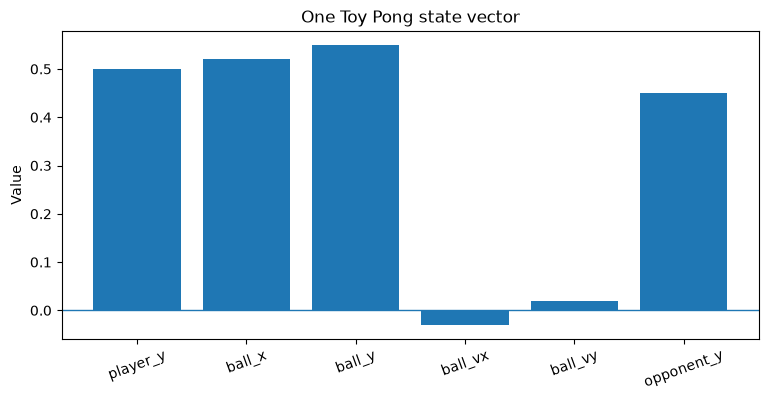

In [2]:
state = np.array([0.50, 0.52, 0.55, -0.03, 0.02, 0.45])
labels = ["player_y","ball_x","ball_y","ball_vx","ball_vy","opponent_y"]

plt.figure(figsize=(9,4))
plt.bar(labels, state)
plt.axhline(0, linewidth=1)
plt.xticks(rotation=20)
plt.ylabel("Value")
plt.title("One Toy Pong state vector")
plt.show()

## 2. Why velocity matters

One still ball position does not tell you whether the ball is arriving or leaving.

Two worlds can have the **same ball position** but require different actions because velocity differs.


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">Hidden consequence of dropping velocity</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">SAME POSITION</text><rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="15">vx &lt; 0: COMING</text><rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="15">vx &gt; 0: LEAVING</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="480.0" y1="82" x2="617.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>


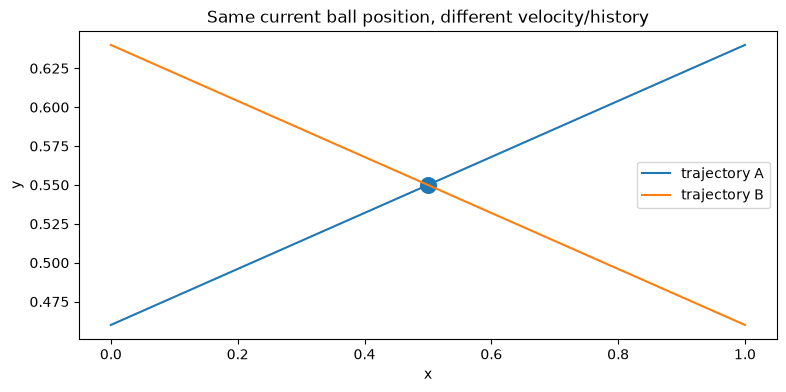

In [3]:
x = np.linspace(0,1,30)
coming = 0.55 + 0.18*(x-0.5)
leaving = 0.55 - 0.18*(x-0.5)

plt.figure(figsize=(9,4))
plt.plot(x, coming, label="trajectory A")
plt.plot(x, leaving, label="trajectory B")
plt.scatter([0.5,0.5],[0.55,0.55],s=120)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Same current ball position, different velocity/history")
plt.legend()
plt.show()

## 3. Policy output

Toy Pong has three actions: `UP`, `STAY`, `DOWN`.

A learned policy maps the represented state to a preference or probability for each action.


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">Policy output</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">STATE VECTOR</text><rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="15">POLICY</text><rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="15">UP / STAY / DOWN</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="480.0" y1="82" x2="617.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>


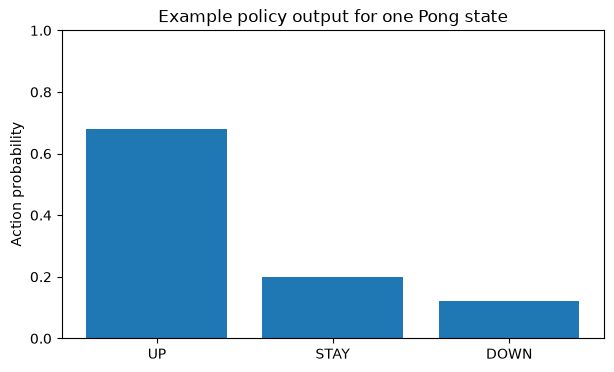

In [4]:
actions = ["UP","STAY","DOWN"]
example_probs = [0.68, 0.20, 0.12]

plt.figure(figsize=(7,4))
plt.bar(actions, example_probs)
plt.ylim(0,1)
plt.ylabel("Action probability")
plt.title("Example policy output for one Pong state")
plt.show()

## 4. State ablation

Now do the thing Fatimah cares about: keep the task and learner fixed, but remove information.

- FULL: position + velocity
- NO VELOCITY: hide velocity
- MINIMAL: only player + ball position

If performance drops, the removed information was decision-relevant.


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">Ablation experiment</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">FULL</text><rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="15">NO VELOCITY</text><rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="15">MINIMAL</text><rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="15">COMPARE OUTCOMES</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="405.0" y1="82" x2="467.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="630.0" y1="82" x2="692.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>


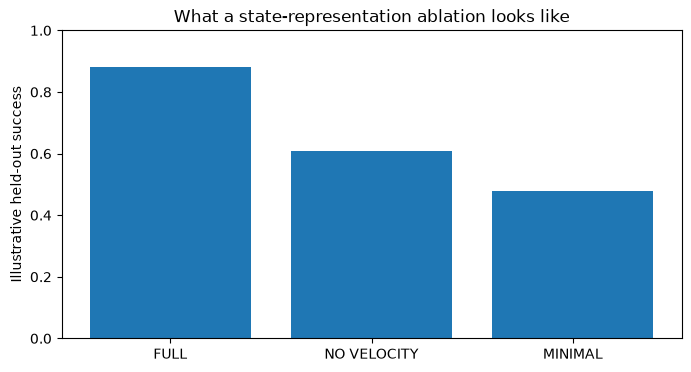

These bars illustrate the experimental logic; run extras/pong/compare_states.py for actual training.


In [5]:
labels = ["FULL","NO VELOCITY","MINIMAL"]
illustrative_success = [0.88, 0.61, 0.48]

plt.figure(figsize=(8,4))
plt.bar(labels, illustrative_success)
plt.ylim(0,1)
plt.ylabel("Illustrative held-out success")
plt.title("What a state-representation ablation looks like")
plt.show()

print("These bars illustrate the experimental logic; run extras/pong/compare_states.py for actual training.")

## 5. Run the actual Toy Pong code later

The repo includes `extras/pong/` with manual play, training, watching, and state comparison.

The conceptual question is now simple:

> Which information must remain distinguishable so the policy can choose correctly?


<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto">
<path d="M0,0 L8,4 L0,8 z" fill="black"/></marker></defs>
<text x="450.0" y="28" text-anchor="middle" font-size="20" font-weight="bold">Same research loop</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="15">OBSERVATION</text><rect x="250.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="325.0" y="88" text-anchor="middle" font-size="15">REPRESENTATION</text><rect x="475.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="550.0" y="88" text-anchor="middle" font-size="15">POLICY</text><rect x="700.0" y="55" rx="12" width="150.0" height="55" fill="white" stroke="black" stroke-width="2"/><text x="775.0" y="88" text-anchor="middle" font-size="15">OUTCOME</text>
<line x1="180.0" y1="82" x2="242.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="405.0" y1="82" x2="467.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/><line x1="630.0" y1="82" x2="692.0" y2="82" stroke="black" stroke-width="2" marker-end="url(#arrow)"/>
</svg>
</div>
